          Timestamp  Electricity_Consumed  Temperature  Humidity  Wind_Speed  \
0  01-01-2024 00:00              0.457786     0.469524  0.396368    0.445441   
1  01-01-2024 00:30              0.351956     0.465545  0.451184    0.458729   
2  01-01-2024 01:00              0.482948     0.285415  0.408289    0.470360   
3  01-01-2024 01:30              0.628838     0.482095  0.512308    0.576241   
4  01-01-2024 02:00              0.335974     0.624741  0.672021    0.373004   

   Avg_Past_Consumption  Anomaly_Label  
0              0.692057              0  
1              0.539874              0  
2              0.614724              0  
3              0.757044              0  
4              0.673981              0  
Dataset shape: (5000, 7)
Preprocessing completed!
Window shape: (4977, 24, 5)
Training data: (3788, 24, 5)
Testing data: (996, 24, 5)
Epoch 1/10
107/107 ━━━━━━━━━━━━━━━━━━━━ 8s 27ms/step - loss: 0.0329 - val_loss: 0.0203
Epoch 2/10
107/107 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step

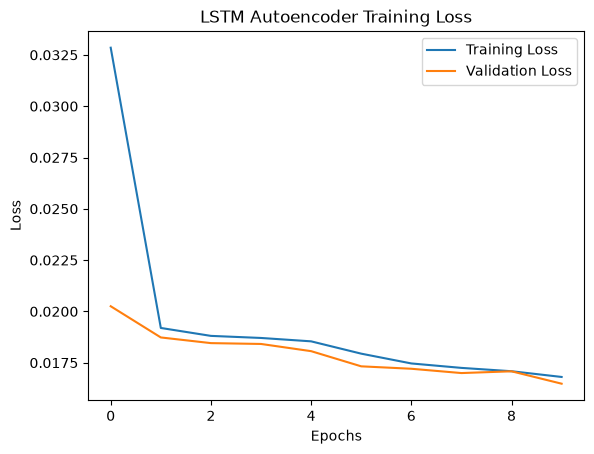

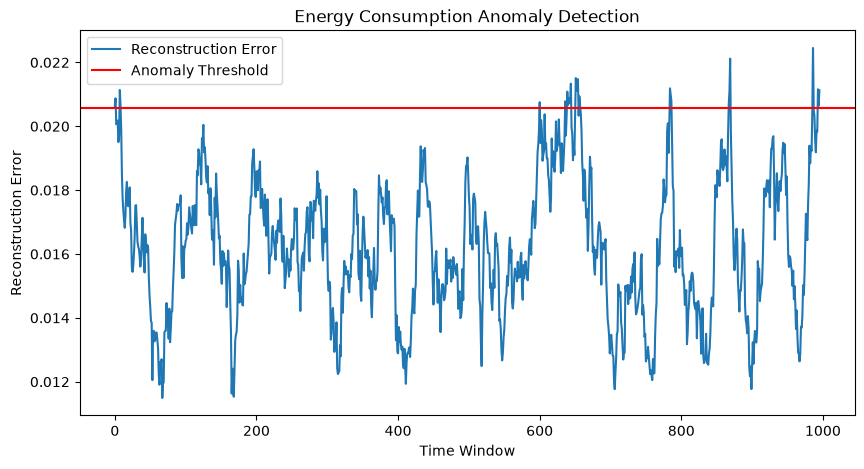

Model saved successfully!


In [5]:

# STEP 1: Import libraries

import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler

# STEP 2: Load dataset

data = pd.read_csv("energy consumption.csv")

print(data.head())
print("Dataset shape:", data.shape)

# STEP 3: Preprocess data

# Convert timestamp into date format
data["Timestamp"] = pd.to_datetime(
    data["Timestamp"],
    format="%d-%m-%Y %H:%M"
)

# Sort data according to timestamp
data = data.sort_values("Timestamp")

# Fill missing values
data = data.ffill().bfill()

# Select input features
features = [
    "Electricity_Consumed",
    "Temperature",
    "Humidity",
    "Wind_Speed",
    "Avg_Past_Consumption"
]

X = data[features].values

# Store actual labels
y = data["Anomaly_Label"].values

# Normalize data
scaler = MinMaxScaler()
X = scaler.fit_transform(X)

print("Preprocessing completed!")

# STEP 4: Create time windows

window_size = 24

X_window = []
y_window = []

for i in range(len(X) - window_size + 1):

    X_window.append(X[i:i + window_size])

    # Label of the last reading in the window
    y_window.append(y[i + window_size - 1])

X_window = np.array(X_window)
y_window = np.array(y_window)

print("Window shape:", X_window.shape)

# STEP 5: Split training and testing data

split = int(0.8 * len(X_window))

X_train = X_window[:split]
X_test = X_window[split:]

y_train = y_window[:split]
y_test = y_window[split:]

# Select only normal windows for training
normal_indices = []

for i in range(len(X_train)):

    if np.all(y_train[i] == 0):
        normal_indices.append(i)

X_train = X_train[normal_indices]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

# STEP 6: Build LSTM Autoencoder

model = tf.keras.Sequential([

    # Encoder
    tf.keras.layers.Input(shape=(window_size, 5)),

    tf.keras.layers.LSTM(64, activation="tanh"),

    # Compressed representation
    tf.keras.layers.RepeatVector(window_size),

    # Decoder
    tf.keras.layers.LSTM(
        64,
        activation="tanh",
        return_sequences=True
    ),

    # Reconstruct original features
    tf.keras.layers.TimeDistributed(
        tf.keras.layers.Dense(5)
    )
])

# STEP 7: Compile model

model.compile(
    optimizer="adam",
    loss="mse"
)

# STEP 8: Train model

history = model.fit(
    X_train,
    X_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1
)

# STEP 9: Calculate reconstruction error

train_output = model.predict(X_train)

train_error = np.mean(
    np.square(X_train - train_output),
    axis=(1, 2)
)

# Set threshold
threshold = np.percentile(train_error, 95)

print("Anomaly Threshold:", threshold)

# STEP 10: Detect anomalies in test data

test_output = model.predict(X_test)

test_error = np.mean(
    np.square(X_test - test_output),
    axis=(1, 2)
)

# Predict anomalies
predictions = (test_error > threshold).astype(int)

print("Anomalies detected:", np.sum(predictions))

# STEP 11: Compare actual and predicted results

actual = (y_test != 0).astype(int)

accuracy = np.mean(predictions == actual) * 100

print("Accuracy:", accuracy, "%")

# STEP 12: Plot training loss

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("LSTM Autoencoder Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

# STEP 13: Plot anomaly detection

plt.figure(figsize=(10, 5))

plt.plot(test_error, label="Reconstruction Error")

plt.axhline(
    threshold,
    color="red",
    label="Anomaly Threshold"
)

plt.title("Energy Consumption Anomaly Detection")
plt.xlabel("Time Window")
plt.ylabel("Reconstruction Error")
plt.legend()
plt.show()

# STEP 14: Save model

model.save("energy_autoencoder.keras")

print("Model saved successfully!")


## Practical 3C – Anomaly Detection in Energy Consumption Data using LSTM Autoencoder

Problem statement: Implement Anomaly Detection in Energy Consumption Data (Smart Grid Dataset) using an Autoencoder. Train an LSTM-based autoencoder on normal energy consumption patterns and detect unusual consumption using reconstruction error.

[Enhancing cybersecurity in virtual power plants by detecting network based cyber attacks using an unsupervised autoencoder approach | Scientific Reports](https://images.openai.com/static-rsc-4/1hrT7bhA7AxMmcJzIOjZhqz1M86GR5j0zmeHuBx7e8s65rlOe6LtzjQWhFVhB2PbQPTQ5o-Aho1HO7GmO8_Z0S88EIsGQfv6zapdX12cB66_kv8BWpXlT7yAtfg0_xkQKRe4JOmg08JesRwhnmJP6kMouIkItULyThRwFpmWeMc?purpose=inline)

[nature.com](https://www.nature.com/articles/s41598-025-01863-w?utm_source=chatgpt.com)

### 1. Understand the practical

Imagine electricity consumption in a household:

- Normal usage: 2 kWh, 3 kWh, 2.5 kWh.
- Unusual usage: suddenly 20 kWh.

The model learns normal electricity consumption patterns. When it sees unusual consumption, it produces a larger reconstruction error.

Basic working:

Energy Consumption Dataset

Timestamp, electricity, temperature, humidity...

Preprocessing

Missing values, normalization, time windows

LSTM Autoencoder

Encoder → Compressed representation → Decoder

Reconstruction Error

Anomaly Detection

Error above threshold = Anomaly

### 2. Explanation of your code

Step 1 – Import libraries

```
import pandas as pdimport numpy as npimport tensorflow as tfimport matplotlib.pyplot as pltfrom sklearn.preprocessing import MinMaxScaler
```

- Pandas: loads and handles dataset.
- NumPy: performs mathematical operations.
- TensorFlow: builds the LSTM Autoencoder.
- Matplotlib: displays graphs.
- MinMaxScaler: normalizes values between 0 and 1.

Step 2 – Load dataset

```
data = pd.read_csv("energy consumption.csv")
```

Loads the energy consumption CSV file.

Your code expects columns such as:

- `Timestamp`
- `Electricity_Consumed`
- `Temperature`
- `Humidity`
- `Wind_Speed`
- `Avg_Past_Consumption`
- `Anomaly_Label`

Step 3 – Preprocessing

```
data["Timestamp"] = pd.to_datetime(    data["Timestamp"],    format="%d-%m-%Y %H:%M")data = data.sort_values("Timestamp")data = data.ffill().bfill()
```

- `to_datetime()` converts timestamp into date/time format.
- `sort_values()` arranges records chronologically.
- `ffill()` fills missing values using the previous value.
- `bfill()` fills remaining missing values using the next value.

Then:

```
features = [    "Electricity_Consumed",    "Temperature",    "Humidity",    "Wind_Speed",    "Avg_Past_Consumption"]X = data[features].valuesy = data["Anomaly_Label"].values
```

`X` contains the input features, while `y` contains actual labels.

Step 4 – Normalization

```
scaler = MinMaxScaler()X = scaler.fit_transform(X)
```

Converts feature values into a range between 0 and 1.

Why? Because electricity consumption, temperature, and humidity have different numerical ranges.

Step 5 – Create time windows

```
window_size = 24
```

This is one of the most important steps.

It means the model looks at 24 consecutive readings together to understand consumption patterns.

For example:

One time window

#### 1

#### 2

#### 3

#### 4

#### ...

#### 21

#### 22

#### 23

#### 24

24 consecutive readings form one window.

```
for i in range(len(X) - window_size + 1):    X_window.append(X[i:i + window_size])    y_window.append(y[i + window_size - 1])
```

- `X[i:i+24]` selects 24 consecutive readings.
- `y[i+23]` takes the label of the last reading in that window.

Step 6 – Split training and testing data

```
split = int(0.8 * len(X_window))X_train = X_window[:split]X_test = X_window[split:]
```

- 80% data for training.
- 20% data for testing.

Then:

```
if np.all(y_train[i] == 0):    normal_indices.append(i)
```

This selects only windows where all 24 readings are normal.

Why? The autoencoder should learn normal energy consumption patterns, not abnormal ones.

Step 7 – Build LSTM Autoencoder

This is the main part of the practical.

```
model = tf.keras.Sequential([    tf.keras.layers.Input(shape=(window_size, 5)),    tf.keras.layers.LSTM(64, activation="tanh"),    tf.keras.layers.RepeatVector(window_size),    tf.keras.layers.LSTM(        64,        activation="tanh",        return_sequences=True    ),    tf.keras.layers.TimeDistributed(        tf.keras.layers.Dense(5)    )])
```

Understand each layer:

| Layer                             | Purpose                                 |
| --------------------------------- | --------------------------------------- |
| `Input(24,5)`                     | 24 readings and 5 features              |
| `LSTM(64)`                        | Learns time-based patterns              |
| `RepeatVector(24)`                | Repeats compressed information 24 times |
| `LSTM(64, return_sequences=True)` | Reconstructs the sequence               |
| `TimeDistributed(Dense(5))`       | Produces 5 features for every time step |

What is LSTM?

LSTM stands for Long Short-Term Memory. It is a type of neural network that learns patterns from sequential data.

For example, it can learn how electricity consumption changes throughout the day.

What is RepeatVector?

It repeats the compressed information so the decoder can reconstruct the complete sequence.

What is TimeDistributed?

It applies the Dense layer separately to every time step.

Step 8 – Compile the model

```
model.compile(    optimizer="adam",    loss="mse")
```

- Adam: optimizer that updates model weights.
- MSE: measures the difference between original and reconstructed data.

Step 9 – Train the model

```
history = model.fit(    X_train,    X_train,    epochs=10,    batch_size=32,    validation_split=0.1)
```

Notice `X_train` is supplied twice.

Why?

The autoencoder learns to reconstruct its own input.

- Epochs = 10: model trains 10 times over the training data.
- Batch size = 32: processes 32 windows at a time.
- Validation split = 0.1: uses 10% of training data for validation.

Step 10 – Calculate reconstruction error

```
train_output = model.predict(X_train)train_error = np.mean(    np.square(X_train - train_output),    axis=(1, 2))
```

This calculates the difference between original and reconstructed windows.

- Low error = normal pattern.
- High error = unusual pattern.

Step 11 – Set threshold

```
threshold = np.percentile(train_error, 95)
```

The 95th percentile is used as the anomaly threshold.

If the reconstruction error exceeds this value, the model identifies the window as anomalous.

Step 12 – Detect anomalies

```
predictions = (test_error > threshold).astype(int)
```

- `1` = anomaly.
- `0` = normal.

Step 13 – Accuracy

```
actual = (y_test != 0).astype(int)accuracy = np.mean(predictions == actual) * 100
```

Compares predicted anomalies with actual anomaly labels.

Step 14 – Plot graphs and save model

The first graph displays training and validation loss.

The second graph displays reconstruction errors and the threshold.

```
model.save("energy_autoencoder.keras")
```

Saves the trained model for future use.

### 3. Important viva questions

Q1. What is an Autoencoder?

A neural network that learns to compress and reconstruct its input data.

Q2. What is LSTM?

Long Short-Term Memory. It is used to learn patterns in sequential data.

Q3. Why do we use LSTM instead of a normal Dense network?

Because energy consumption depends on time and previous readings. LSTM can learn these temporal relationships.

Q4. What is a time window?

A group of consecutive readings used together as one input to the model.

Q5. Why do we normalize data?

To bring different feature values into a common range between 0 and 1.

Q6. Why train only on normal data?

So the model learns typical consumption patterns and can identify unusual patterns.

Q7. What is MSE?

Mean Squared Error. It measures the squared difference between original and reconstructed values.

Q8. What is the purpose of the threshold?

It decides whether reconstruction error is high enough to classify a window as anomalous.

Q9. What does `return_sequences=True` do?

It makes the LSTM return an output for every time step instead of only the final output.

Q10. What is the difference between LSTM and CNN?

CNN extracts spatial or local patterns, while LSTM is designed to learn sequential and time-dependent patterns.

### 4. What to tell the examiner

You can explain it like this:

"I implemented anomaly detection on energy consumption data using an LSTM Autoencoder. First, I loaded the Smart Grid dataset and handled missing values. Then I normalized the features and created time windows of 24 readings. I selected only normal windows for training. Next, I built an LSTM Autoencoder with an encoder and decoder. The model learns normal energy consumption patterns by reconstructing its input. Finally, I calculated reconstruction errors, set a 95th percentile threshold, and classified windows with errors above the threshold as anomalies."

### 5. Quick revision

| Parameter        | Value            |
| ---------------- | ---------------- |
| Model            | LSTM Autoencoder |
| Input features   | 5                |
| Window size      | 24               |
| Training data    | 80%              |
| Normal data only | Yes              |
| LSTM units       | 64               |
| Optimizer        | Adam             |
| Loss             | MSE              |
| Epochs           | 10               |
| Batch size       | 32               |
| Threshold        | 95th percentile  |

One technical point

Your code fits the practical well, but there are two improvements worth knowing:

1. `MinMaxScaler` is currently fitted on all data before the train/test split. Ideally, fit it only on training data to avoid data leakage.
2. Your threshold is calculated from training reconstruction errors. A separate normal validation set is better for choosing the threshold.

Also, the accuracy calculation is only meaningful if your labels use `0 = normal` and non-zero = anomaly, as assumed by your code.